# Chapter 6: Same model, opposite threshold: where does Rohan draw his line?

*The transfer: the same model, a lending business, the opposite threshold · also searched as: credit risk threshold, cost matrix, loan approval model*

**Who needs the answer.** Rohan Desai, head of risk at Kalpa Financial Services, who has heard about Retail's model and asks whether the same approach can score loan applicants. In his book a false approval (lending to someone who defaults) costs Rs 60,000 and a wrongful rejection (turning away someone who would have repaid) costs Rs 3,000 of lost interest.

**The questions on the way.** How many good loans does one default wipe out? Where does Rohan's line sit, said on the same quantity as Retail's? What goes wrong if Retail's rule is copied across? How do you say it to Rohan in one sentence?

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

FALSE_APPROVAL, WRONG_REJECTION = 60000, 3000
print(f"one default wipes out {FALSE_APPROVAL // WRONG_REJECTION} good loans' interest: {FALSE_APPROVAL // WRONG_REJECTION} x Rs {WRONG_REJECTION:,} = Rs {FALSE_APPROVAL:,}")

one default wipes out 20 good loans' interest: 20 x Rs 3,000 = Rs 60,000


## Where does Rohan's line sit?

**Predict before you run.** Lend when P(repay) is above what? (a) 0.05, (b) 0.50, (c) 0.83, (d) 0.95.

Retail:    nudge when P(buy)   is above 0.032  (1 in 31)
Financial: lend  when P(repay) is above 0.952  (20 in 21)
said the other way: lend only when P(default) is below 0.048


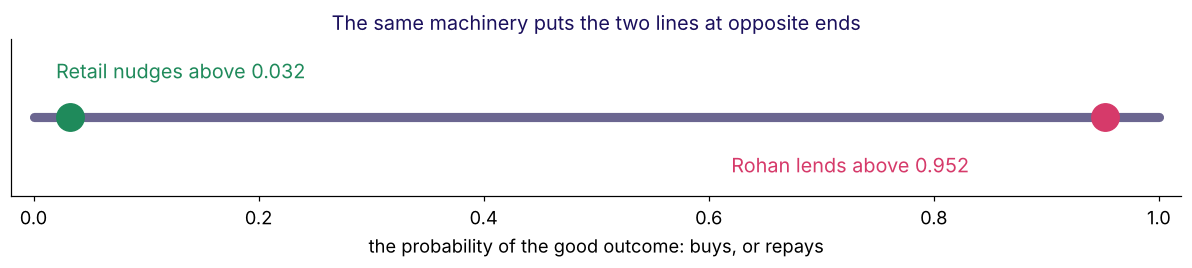

In [2]:
lend_above = FALSE_APPROVAL / (FALSE_APPROVAL + WRONG_REJECTION)
nudge_above = 40 / (40 + 1200)
print(f"Retail:    nudge when P(buy)   is above {nudge_above:.3f}  (1 in 31)")
print(f"Financial: lend  when P(repay) is above {lend_above:.3f}  (20 in 21)")
print(f"said the other way: lend only when P(default) is below {1 - lend_above:.3f}")
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.plot([0, 1], [0, 0], color=MUTED, lw=6, solid_capstyle="round")
ax.scatter([nudge_above], [0], s=320, color=GREEN, zorder=5); ax.annotate("Retail nudges above 0.032", (nudge_above, 0), (0.02, 0.5), color=GREEN, fontsize=13)
ax.scatter([lend_above], [0], s=320, color=ROSE, zorder=5); ax.annotate("Rohan lends above 0.952", (lend_above, 0), (0.62, -0.7), color=ROSE, fontsize=13)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-1, 1); ax.set_yticks([]); ax.set_xlabel("the probability of the good outcome: buys, or repays")
ax.set_title("The same machinery puts the two lines at opposite ends", color=INK); plt.tight_layout(); plt.show()

**What happened.** The answer is (d). A default costs twenty good loans' interest, so Rohan needs at least 20 repayers in every 21 approvals: P(repay) above 0.952. Retail's nudge pays above 0.032. Both lines come from the same formula; the dearer mistake changed sides, so precision leads in lending and the line moves to the other end.

## What does each line cost on twenty applicants?

In [3]:
import numpy as np, pandas as pd
# Invented: twenty loan applicants at Kalpa Financial Services, the model's P(repay), and what happened.
apps = pd.DataFrame({
    "applicant": [f"R{i:02d}" for i in range(1, 21)],
    "p_repay": [0.995, 0.99, 0.985, 0.98, 0.975, 0.97, 0.965, 0.96, 0.94, 0.92,
                0.90, 0.88, 0.85, 0.80, 0.75, 0.70, 0.60, 0.55, 0.45, 0.30],
    "repaid":  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0],
})
print(apps.to_string(index=False))

def bill_at(t):
    lend = apps.p_repay >= t; good = apps.repaid == 1
    fa = int((lend & ~good).sum()); wr = int((~lend & good).sum())
    return int(lend.sum()), fa, wr, fa * FALSE_APPROVAL + wr * WRONG_REJECTION
for name, t in (("Retail's line copied across, 0.032", nudge_above), ("the default 0.5", 0.5), ("0.9", 0.9), ("Rohan's line, 0.952", lend_above), ("reject everyone", 1.01)):
    n, fa, wr, b = bill_at(t)
    print(f"{name:<36} lends {n:>2}  defaults approved {fa}  good turned away {wr:>2}  bill Rs {b:>8,}")

applicant  p_repay  repaid
      R01    0.995       1
      R02    0.990       1
      R03    0.985       1
      R04    0.980       1
      R05    0.975       1
      R06    0.970       1
      R07    0.965       1
      R08    0.960       1
      R09    0.940       1
      R10    0.920       1
      R11    0.900       0
      R12    0.880       1
      R13    0.850       1
      R14    0.800       0
      R15    0.750       1
      R16    0.700       0
      R17    0.600       1
      R18    0.550       0
      R19    0.450       0
      R20    0.300       0
Retail's line copied across, 0.032   lends 20  defaults approved 6  good turned away  0  bill Rs  360,000
the default 0.5                      lends 18  defaults approved 4  good turned away  0  bill Rs  240,000
0.9                                  lends 11  defaults approved 1  good turned away  4  bill Rs   72,000
Rohan's line, 0.952                  lends  8  defaults approved 0  good turned away  6  bill Rs   18,000
reject ev

## The trap: copying Retail's rule across

A hurried analyst reuses Marketing's code with its threshold of 0.032 and approves everyone, all six defaulters included: a bill of Rs 360,000 on twenty applicants, against Rs 18,000 at Rohan's line. The same model is fine; the line was set for the wrong business. The check is to state both lines on the same quantity (the chance of the good outcome) with the costs that set them; the fix is to re-derive the line from Rohan's two prices.

In [4]:
b_copy = bill_at(nudge_above)[3]; b_rohan = bill_at(lend_above)[3]
print(f"copied line: Rs {b_copy:,}; Rohan's line: Rs {b_rohan:,}")
print("PASS  Rohan's line is 20 in 21" if abs(lend_above - 20 / 21) < 1e-12 else "CHECK line")
print("PASS  Rohan's line has the lowest bill of the five" if b_rohan == min(bill_at(t)[3] for t in (nudge_above, 0.5, 0.9, lend_above, 1.01)) else "CHECK bills")

copied line: Rs 360,000; Rohan's line: Rs 18,000
PASS  Rohan's line is 20 in 21
PASS  Rohan's line has the lowest bill of the five


## A second route: say it as the chance of default

Rohan's committee speaks in default risk. Lending when P(repay) is above 0.952 is lending when P(default) is below `3,000 / 63,000 = 0.048`, about 5 percent. The cell checks both phrasings approve the same applicants.

In [5]:
by_repay = apps[apps.p_repay >= lend_above].applicant.tolist()
by_default = apps[(1 - apps.p_repay) <= WRONG_REJECTION / (FALSE_APPROVAL + WRONG_REJECTION) + 1e-12].applicant.tolist()
print(f"approved by P(repay): {by_repay}")
print("PASS  the two phrasings approve the same applicants" if by_repay == by_default else "CHECK phrasing")

approved by P(repay): ['R01', 'R02', 'R03', 'R04', 'R05', 'R06', 'R07', 'R08']
PASS  the two phrasings approve the same applicants


## What did this chapter establish?

| Business | Dearer mistake | Act when | Metric that leads |
|---|---|---|---|
| Kalpa Retail nudge | missing a buyer, Rs 1,200 | P(buy) above 0.032 | recall |
| Kalpa Financial loan | approving a defaulter, Rs 60,000 | P(repay) above 0.952 | precision |

**The rule.** Same model, same formula, opposite line, because the expensive error changed sides. It holds only while the probabilities are honest and the costs are right; if Rohan's loss on a default halves, his line falls.

**In the interview.** "The same model in retail and in lending: why are the thresholds opposite, and how do you explain it to each business?" To Rohan: "We lend only when at least 20 in 21 applicants like this one repay, because one default costs the interest on twenty good loans."

The practice lab runs this on German Credit's 1,000 real applicants, whose documented cost matrix is 5 to 1.